In [1]:
from keras.datasets import mnist
from keras.layers import Input,Conv2D,Activation,Dense,Lambda,Flatten,Embedding,PReLU,BatchNormalization
from keras.models import Model
import keras.backend as K
from keras.utils import to_categorical
import numpy as np
from keras.callbacks import EarlyStopping

In [2]:
from keras.datasets import mnist
# load data

(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')
x_train /= 255
x_test /= 255

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [3]:
inputs = Input((28, 28, 1))
x = Conv2D(32, (3, 3))(inputs)
x = BatchNormalization()(x)
x = PReLU()(x)
x = Conv2D(32, (3, 3))(x)
x = BatchNormalization()(x)
x = PReLU()(x)
x = Conv2D(64, (5, 5))(x)
x = BatchNormalization()(x)
x = PReLU()(x)
x = Conv2D(64, (5, 5))(x)
x = BatchNormalization()(x)
x = PReLU()(x)
x = Conv2D(128, (7, 7))(x)
x = BatchNormalization()(x)
x = PReLU()(x)
x = Conv2D(128, (7, 7))(x)
x = BatchNormalization()(x)
x = PReLU()(x)
x = Flatten()(x)
x = Dense(2)(x)
out1 = PReLU(name="out1")(x)
out2 = Dense(10, activation="softmax")(out1)

model=Model(inputs,out2)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_re_lu (PReLU)                 │ (None, 26, 26, 32)     │        21,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 24, 24, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_re_lu_1 (PReLU)               │ (None, 24, 24, 32)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 20, 20, 64)     │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 20, 20, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_re_lu_2 (PReLU)               │ (None, 20, 20, 64)     │        25,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_re_lu_3 (PReLU)               │ (None, 16, 16, 64)     │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 10, 10, 128)    │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 10, 10, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_re_lu_4 (PReLU)               │ (None, 10, 10, 128)    │        12,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 4, 4, 128)      │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 4, 4, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_re_lu_5 (PReLU)               │ (None, 4, 4, 128)      │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │         4,098 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ out1 (PReLU)                    │ (None, 2)              │             

 Total params: 1,470,594 (5.61 MB)

 Trainable params: 1,469,698 (5.61 MB)

 Non-trainable params: 896 (3.50 KB)

In [4]:
from keras.layers import Input, Embedding, Lambda
from keras.models import Model
import keras.backend as K

lambda_c = 1
input_ = Input(shape=(1,))

# Embedding layer
centers = Embedding(10, 2)(input_)


# Lambda layer with explicitly defined output_shape
import tensorflow as tf

# Lambda layer with TensorFlow operations

# intra_loss = Lambda(
#     lambda x: tf.reduce_sum(tf.square(x[0] - x[1][:, 0]), axis=1, keepdims=True),
#     output_shape=(1,)
# )([out1, centers])



# Model definition

# model_center_loss = Model([inputs, input_], [out2, intra_loss])

model = Model(inputs=inputs, outputs=out2)



# Compile the model

# model_center_loss.compile(
#     optimizer="sgd",
#     loss=["categorical_crossentropy", lambda y_true, y_pred: y_pred],
#     loss_weights=[1, lambda_c / 2.],
#     metrics=["accuracy", None]
# )

model.compile(
    optimizer="sgd",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)



# Model summary
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_re_lu (PReLU)                 │ (None, 26, 26, 32)     │        21,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 24, 24, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_re_lu_1 (PReLU)               │ (None, 24, 24, 32)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 20, 20, 64)     │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 20, 20, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_re_lu_2 (PReLU)               │ (None, 20, 20, 64)     │        25,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_re_lu_3 (PReLU)               │ (None, 16, 16, 64)     │        16,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 10, 10, 128)    │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 10, 10, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_re_lu_4 (PReLU)               │ (None, 10, 10, 128)    │        12,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 4, 4, 128)      │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 4, 4, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_re_lu_5 (PReLU)               │ (None, 4, 4, 128)      │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │         4,098 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ out1 (PReLU)                    │ (None, 2)              │             

 Total params: 1,470,594 (5.61 MB)

 Trainable params: 1,469,698 (5.61 MB)

 Non-trainable params: 896 (3.50 KB)

In [5]:
x_train=x_train.astype("float32")
x_test=x_test.astype("float32")
x_train/=255.
x_test/=255.
x_train=np.expand_dims(x_train,axis=-1)
x_test=np.expand_dims(x_test,axis=-1)

y_train_one_hot=to_categorical(y_train)
y_test_one_hot=to_categorical(y_test)

print(x_train.shape)
print(y_train.shape)
print(y_train_one_hot.shape)

(60000, 28, 28, 1)
(60000,)
(60000, 10)


In [6]:
dummy_matrix1=np.zeros((x_train.shape[0],1))
dummy_matrix2=np.zeros((x_test.shape[0],1))

# model_center_loss.fit(x=[x_train,y_train],y=[y_train_one_hot,dummy_matrix1],
#                      batch_size=512,epochs=100,verbose=1,validation_data=([x_test,y_test],[y_test_one_hot,dummy_matrix2]),
#                      callbacks=[EarlyStopping(monitor="val_loss",patience=20)])

model.fit(
    x=x_train,
    y=y_train_one_hot,
    batch_size=512,
    epochs=100,
    validation_data=(x_test, y_test_one_hot),
    callbacks=[EarlyStopping(monitor="val_loss", patience=20)]
)


Epoch 1/100
118/118 ━━━━━━━━━━━━━━━━━━━━ 31s 145ms/step - accuracy: 0.2121 - loss: 2.0527 - val_accuracy: 0.1135 - val_loss: 2.3099
Epoch 2/100
118/118 ━━━━━━━━━━━━━━━━━━━━ 21s 74ms/step - accuracy: 0.5266 - loss: 1.1901 - val_accuracy: 0.0974 - val_loss: 2.4757
Epoch 3/100
118/118 ━━━━━━━━━━━━━━━━━━━━ 9s 75ms/step - accuracy: 0.6720 - loss: 0.7709 - val_accuracy: 0.1135 - val_loss: 3.3107
Epoch 4/100
118/118 ━━━━━━━━━━━━━━━━━━━━ 10s 77ms/step - accuracy: 0.7930 - loss: 0.5534 - val_accuracy: 0.1543 - val_loss: 5.7737
Epoch 5/100
118/118 ━━━━━━━━━━━━━━━━━━━━ 9s 78ms/step - accuracy: 0.9238 - loss: 0.3985 - val_accuracy: 0.1041 - val_loss: 6.6356
Epoch 6/100
118/118 ━━━━━━━━━━━━━━━━━━━━ 11s 80ms/step - accuracy: 0.9437 - loss: 0.2868 - val_accuracy: 0.4129 - val_loss: 1.7890
Epoch 7/100
118/118 ━━━━━━━━━━━━━━━━━━━━ 11s 85ms/step - accuracy: 0.9544 - loss: 0.2207 - val_accuracy: 0.8955 - val_loss: 0.4103
Epoch 8/100
118/118 ━━━━━━━━━━━━━━━━━━━━ 10s 84ms/step - accuracy: 0.9594 - loss: 0.

In [7]:
# Create a model that outputs the desired layer's output
layer_name = 'out1'  # Replace with the correct layer name
intermediate_layer_model = Model(inputs=model.input, outputs=model.get_layer(layer_name).output)

# Get the intermediate features
test_features = intermediate_layer_model.predict(x_test)
print(test_features.shape)

# Compute test centers
test_centers = np.dot(np.transpose(y_test_one_hot), test_features)
test_centers_count = np.sum(np.transpose(y_test_one_hot), axis=1, keepdims=True)
test_centers /= test_centers_count
print(test_centers.shape)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step
(10000, 2)
(10, 2)


In [3]:
# from sklearn.manifold import TSNE
# import matplotlib.pyplot as plt

# tsne = TSNE(n_components=2, random_state=42)
# features_2d = tsne.fit_transform(test_features)

# plt.scatter(features_2d[:, 0], features_2d[:, 1], c=y_test, s=5, cmap="tab10")
# plt.title("t-SNE projection of 100D embedding")
# plt.show()


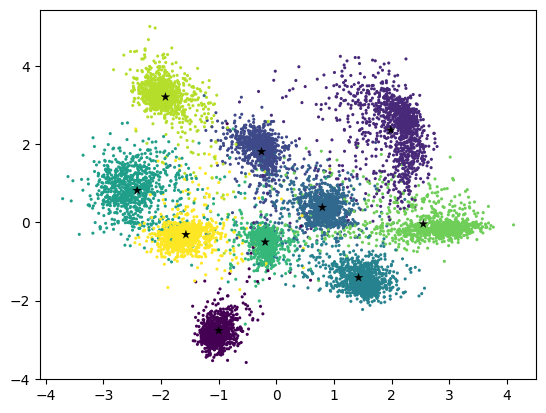

In [ ]:
from matplotlib import pyplot as plt
%matplotlib inline
plt.scatter(test_features[:,0],test_features[:,1],c=y_test,edgecolor="none",s=5)
plt.scatter(test_centers[:,0],test_centers[:,1],c="black",marker="*",edgecolor="none",s=50)
plt.show()

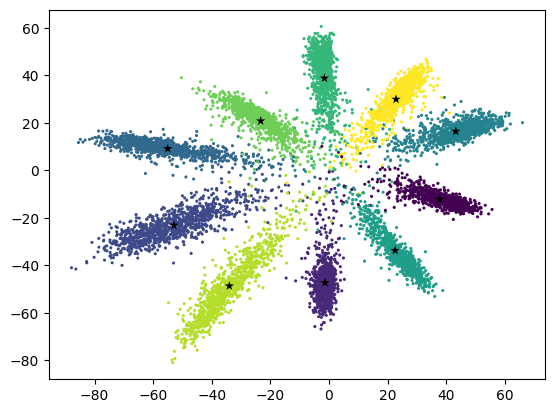

In [11]:
from matplotlib import pyplot as plt
%matplotlib inline
plt.scatter(test_features[:,0],test_features[:,1],c=y_test,edgecolor="none",s=5)
plt.scatter(test_centers[:,0],test_centers[:,1],c="black",marker="*",edgecolor="none",s=50)
plt.show()